# Table of Contents
- [8.0 Introduction: thinking in frequencies](#intro)
- [8.1 The Discrete Fourier Transform (DFT)](#dft)
- [8.2 The Fast Fourier Transform (FFT)](#fft)
- [8.3 Using `numpy.fft`: frequencies and the power spectrum](#numpy-fft)
- [8.4 Sampling and aliasing](#aliasing)
- [8.5 Spectral leakage and windowing](#windowing)
- [8.6 Filtering a noisy signal](#filtering)
- [8.7 The convolution theorem](#convolution)
- [8.8 Spectral differentiation](#spectral-diff)
- [Problems](#problems)

# 8.0 Introduction: thinking in frequencies <a class="anchor" id="intro"></a>
Fourier's great insight was that (almost) any function can be built from sines and cosines. The **Fourier transform**

$$\tilde f(\nu) = \int_{-\infty}^{\infty} f(t)\,e^{-2\pi i \nu t}\,dt, \qquad f(t) = \int_{-\infty}^{\infty} \tilde f(\nu)\,e^{2\pi i \nu t}\,d\nu$$

tells us how much of each frequency $\nu$ is present in a signal. Physicists use it constantly: spectroscopy, diffraction (the far-field pattern of an aperture *is* its Fourier transform - see the Optics applications notebook), the momentum-space wavefunction in QM, solving linear PDEs, signal processing, and the analysis of every oscilloscope trace and gravitational-wave detector output.

In practice, our data is a finite list of samples, so we need a *discrete* version. And thanks to one of the most important algorithms of the 20th century - the **FFT** - we can compute it astonishingly fast.

In [1]:
# BLOCK 8.0.1
import numpy as np
import matplotlib.pyplot as plt

# 8.1 The Discrete Fourier Transform (DFT) <a class="anchor" id="dft"></a>
Given $N$ samples $f_n = f(t_n)$ taken at equal intervals $\Delta t$, $t_n = n\Delta t$, the DFT is

$$F_k = \sum_{n=0}^{N-1} f_n\, e^{-2\pi i kn/N}, \qquad k = 0, 1, \dots, N-1,$$

and the inverse is $f_n = \frac{1}{N}\sum_k F_k e^{2\pi i kn/N}$. The coefficient $F_k$ corresponds to frequency $\nu_k = k/(N\Delta t)$. It is just the Fourier integral approximated with the rectangle rule!

Written as a matrix, $F = W f$ with $W_{kn} = e^{-2\pi i kn/N}$, so the direct computation costs $\mathcal{O}(N^2)$.

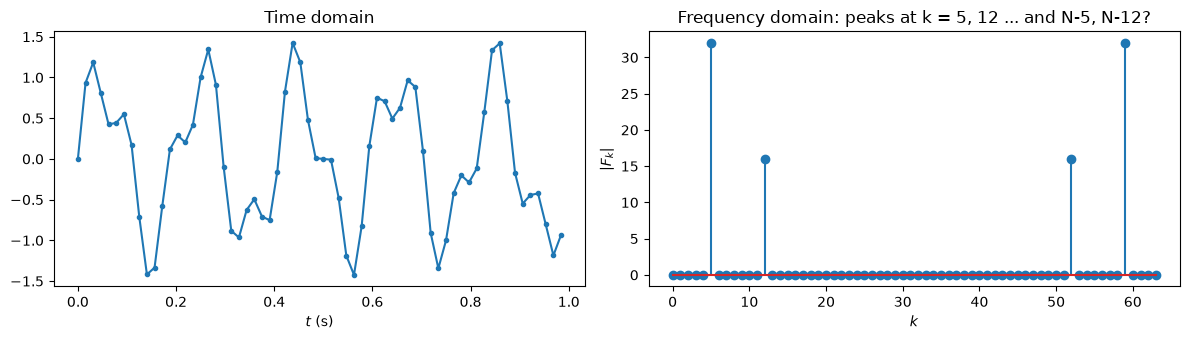

Matches numpy? True


In [2]:
# BLOCK 8.1.1
def dft(f):
    N = len(f)
    n = np.arange(N)
    k = n.reshape((N, 1))
    W = np.exp(-2j*np.pi*k*n/N)          # the N x N DFT matrix
    return W @ f

# A test signal: 5 Hz and 12 Hz sine waves sampled at 64 Hz for 1 s
fs = 64
t = np.arange(fs) / fs
signal = np.sin(2*np.pi*5*t) + 0.5*np.sin(2*np.pi*12*t)
F = dft(signal)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))
ax1.plot(t, signal, '.-'); ax1.set_xlabel('$t$ (s)'); ax1.set_title('Time domain')
ax2.stem(np.arange(len(F)), np.abs(F)); ax2.set_xlabel('$k$'); ax2.set_ylabel('$|F_k|$')
ax2.set_title('Frequency domain: peaks at k = 5, 12 ... and N-5, N-12?')
plt.tight_layout(); plt.show()
print('Matches numpy?', np.allclose(F, np.fft.fft(signal)))

Why are there *mirror* peaks at $k=59$ and $k=52$? Because $e^{-2\pi i (N-k)n/N} = e^{+2\pi i kn/N}$: index $N-k$ is the same as frequency $-k$. For a **real** signal $F_{N-k}=F_k^*$, so the upper half of the array holds the negative frequencies and carries no new information.

# 8.2 The Fast Fourier Transform (FFT) <a class="anchor" id="fft"></a>
In 1965 Cooley and Tukey (rediscovering an idea Gauss had in 1805!) noticed that a DFT of length $N$ can be split into two DFTs of length $N/2$ - one over the even samples and one over the odd ones:

$$F_k = \underbrace{\sum_{m} f_{2m}\,e^{-2\pi i km/(N/2)}}_{E_k} + e^{-2\pi i k/N}\underbrace{\sum_m f_{2m+1}\,e^{-2\pi i km/(N/2)}}_{O_k}.$$

Because $E_k$ and $O_k$ are periodic with period $N/2$, we also get $F_{k+N/2} = E_k - e^{-2\pi i k/N}O_k$ for free. Applying the trick **recursively** until the DFTs have length 1 (when $N$ is a power of 2) gives a cost of $\mathcal{O}(N\log_2 N)$ instead of $\mathcal{O}(N^2)$. For $N = 10^6$ that's the difference between $10^{12}$ and $2\times10^7$ operations - a seconds-versus-weeks difference.

Recursion, as promised in the introduction, makes the code beautifully short:

In [3]:
# BLOCK 8.2.1
def fft_recursive(f):
    N = len(f)
    if N == 1:
        return np.array(f, dtype=complex)
    if N % 2:
        raise ValueError('length must be a power of 2')
    even = fft_recursive(f[0::2])
    odd = fft_recursive(f[1::2])
    twiddle = np.exp(-2j*np.pi*np.arange(N//2)/N) * odd
    return np.concatenate([even + twiddle, even - twiddle])

print('Matches numpy?', np.allclose(fft_recursive(signal), np.fft.fft(signal)))

Matches numpy? True


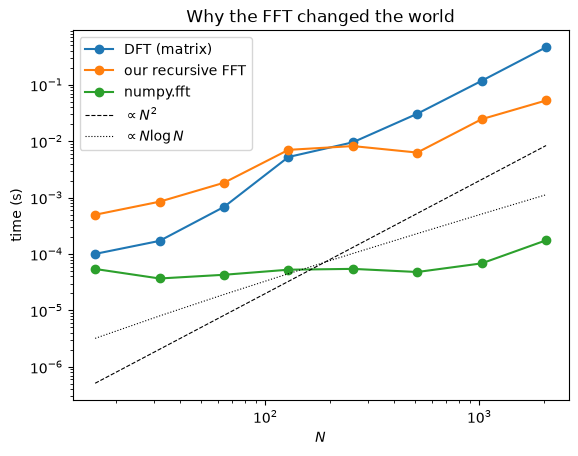

In [4]:
# BLOCK 8.2.2
import time
sizes = 2**np.arange(4, 12)
timings = {'DFT (matrix)': [], 'our recursive FFT': [], 'numpy.fft': []}
for N in sizes:
    x = np.random.default_rng(0).random(N)
    for name, func in [('DFT (matrix)', dft), ('our recursive FFT', fft_recursive), ('numpy.fft', np.fft.fft)]:
        t0 = time.perf_counter()
        for _ in range(3):
            func(x)
        timings[name].append((time.perf_counter() - t0)/3)

for name, ts in timings.items():
    plt.loglog(sizes, ts, 'o-', label=name)
plt.loglog(sizes, 2e-9*sizes**2.0, 'k--', lw=0.8, label=r'$\propto N^2$')
plt.loglog(sizes, 5e-8*sizes*np.log2(sizes), 'k:', lw=0.8, label=r'$\propto N\log N$')
plt.xlabel('$N$'); plt.ylabel('time (s)'); plt.legend(); plt.title('Why the FFT changed the world')
plt.show()

(Our recursive FFT has the right scaling, but Python function-call overhead makes it slower than the matrix DFT for small $N$; numpy's compiled FFT is in a league of its own.)

# 8.3 Using `numpy.fft`: frequencies and the power spectrum <a class="anchor" id="numpy-fft"></a>
The key functions:
- `np.fft.fft(f)` / `np.fft.ifft(F)` - forward and inverse transforms.
- `np.fft.rfft(f)` - for real input, returns only the non-negative frequencies (half the work).
- `np.fft.fftfreq(N, d=dt)` / `np.fft.rfftfreq(N, d=dt)` - the frequency (in Hz if `dt` is in s) of each output element. Always use these rather than working the frequencies out by hand!
- `np.fft.fftshift` - reorder so zero frequency is in the middle (nice for plotting).

The **power spectrum** $|F_k|^2$ tells us how the signal's energy is distributed over frequency.

**Example:** a damped oscillator ringing at 50 Hz with quality factor $Q$. The spectral peak has a width $\Delta\nu\approx\nu_0/Q$.

peak at 50.00 Hz, FWHM ≈ 1.20 Hz (expected nu0/Q = 1.25 Hz)


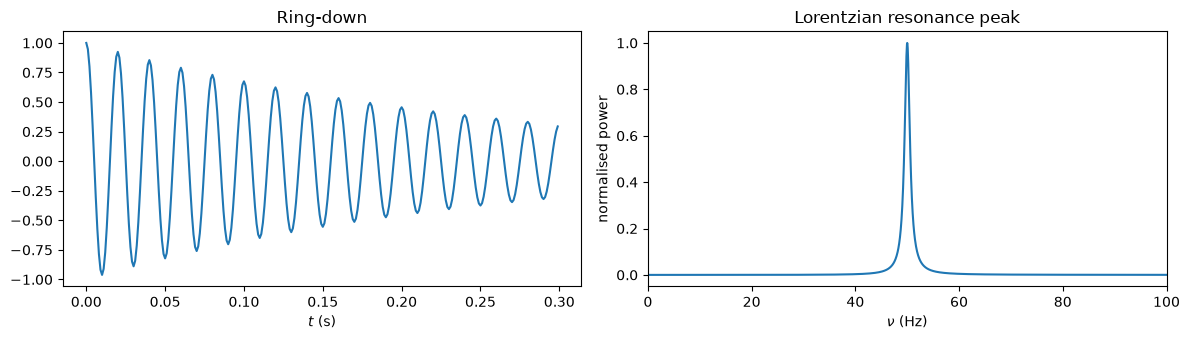

In [5]:
# BLOCK 8.3.1
fs = 1000                                   # sample rate (Hz)
t = np.arange(0, 20, 1/fs)              # a long record gives fine frequency resolution 1/T = 0.05 Hz
nu0, Q = 50.0, 40
gamma = np.pi*nu0/Q                         # amplitude decay rate
x = np.exp(-gamma*t)*np.cos(2*np.pi*nu0*t)

X = np.fft.rfft(x)
nu = np.fft.rfftfreq(len(x), d=1/fs)
P = np.abs(X)**2

half_max = nu[P > P.max()/2]
print(f'peak at {nu[np.argmax(P)]:.2f} Hz, FWHM ≈ {half_max[-1] - half_max[0]:.2f} Hz (expected nu0/Q = {nu0/Q:.2f} Hz)')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))
ax1.plot(t[:300], x[:300]); ax1.set_xlabel('$t$ (s)'); ax1.set_title('Ring-down')
ax2.plot(nu, P/P.max()); ax2.set_xlim(0, 100); ax2.set_xlabel(r'$\nu$ (Hz)'); ax2.set_ylabel('normalised power')
ax2.set_title('Lorentzian resonance peak')
plt.tight_layout(); plt.show()

# 8.4 Sampling and aliasing <a class="anchor" id="aliasing"></a>
Sampling at rate $f_s$ we can only represent frequencies up to the **Nyquist frequency** $f_N = f_s/2$ (two samples per period). A signal above $f_N$ doesn't disappear - it masquerades as a lower frequency $|f - m f_s|$. This is **aliasing**, the reason wagon wheels appear to turn backwards in films, and why audio is sampled at 44.1 kHz (just above twice the 20 kHz limit of human hearing).

The **Nyquist-Shannon sampling theorem** guarantees that a signal containing no frequencies above $f_N$ can be perfectly reconstructed from its samples.

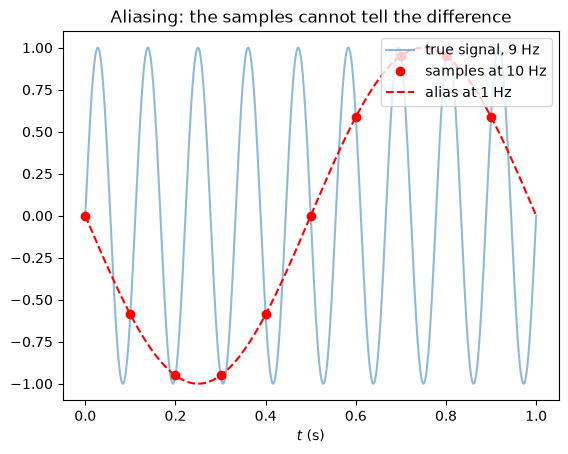

In [6]:
# BLOCK 8.4.1
fs = 10                                      # Hz -> Nyquist frequency 5 Hz
t_fine = np.linspace(0, 1, 1000)
t_s = np.arange(0, 1, 1/fs)
f_true = 9                                   # Hz, above Nyquist!
plt.plot(t_fine, np.sin(2*np.pi*f_true*t_fine), alpha=0.5, label=f'true signal, {f_true} Hz')
plt.plot(t_s, np.sin(2*np.pi*f_true*t_s), 'ro', label=f'samples at {fs} Hz')
plt.plot(t_fine, np.sin(2*np.pi*(f_true - fs)*t_fine), 'r--', label=f'alias at {abs(f_true - fs)} Hz')
plt.xlabel('$t$ (s)'); plt.legend(loc='upper right'); plt.title('Aliasing: the samples cannot tell the difference')
plt.show()

# 8.5 Spectral leakage and windowing <a class="anchor" id="windowing"></a>
The DFT implicitly assumes the signal repeats periodically with period $N\Delta t$. If an integer number of cycles doesn't fit in the record, there's a jump where the end wraps round to the start, and the peak "leaks" into neighbouring bins. Multiplying by a smooth **window** that tapers to zero at both ends (e.g. the Hann window $w_n = \sin^2(\pi n/N)$) suppresses the leakage, at the cost of a slightly wider central peak. This matters enormously when looking for a faint signal next to a bright one.

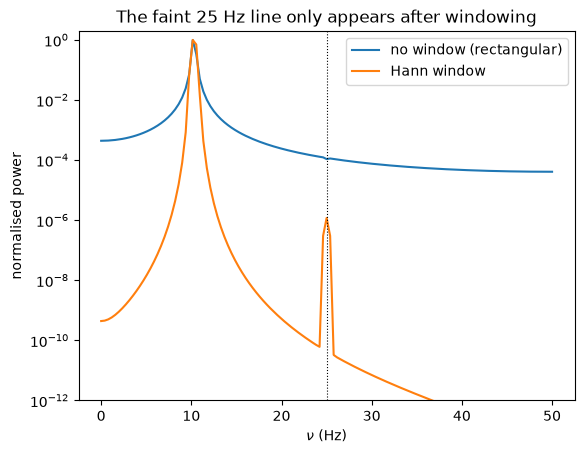

In [7]:
# BLOCK 8.5.1
fs, N = 100, 256
t = np.arange(N)/fs
x = np.sin(2*np.pi*10.3*t) + 1e-3*np.sin(2*np.pi*25*t)    # a faint line at 25 Hz
nu = np.fft.rfftfreq(N, 1/fs)
for name, w in [('no window (rectangular)', np.ones(N)), ('Hann window', np.hanning(N))]:
    P = np.abs(np.fft.rfft(x*w))**2
    plt.semilogy(nu, P/P.max(), label=name)
plt.axvline(25, color='k', ls=':', lw=0.8)
plt.xlabel(r'$\nu$ (Hz)'); plt.ylabel('normalised power'); plt.ylim(1e-12, 2); plt.legend()
plt.title('The faint 25 Hz line only appears after windowing')
plt.show()

# 8.6 Filtering a noisy signal <a class="anchor" id="filtering"></a>
In the frequency domain, filtering is trivial: transform, set the unwanted coefficients to zero (or multiply by a smooth filter response), and transform back. Here we pull a weak signal out of noise with a low-pass filter.

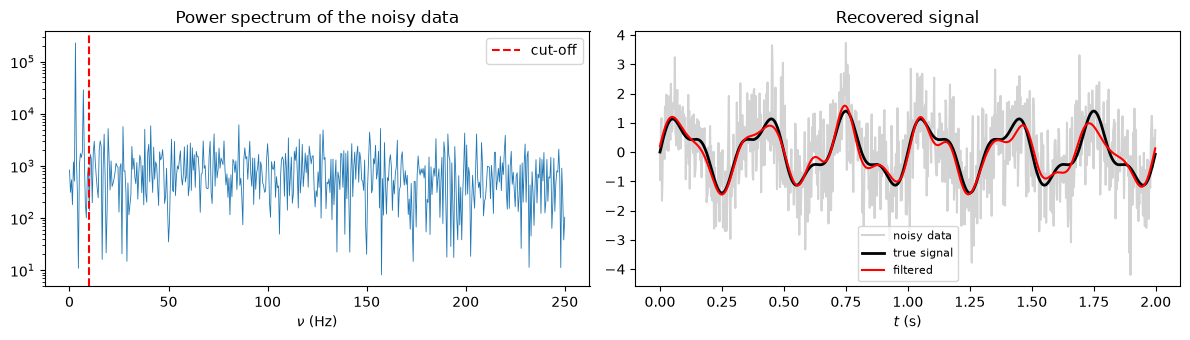

In [8]:
# BLOCK 8.6.1
rng = np.random.default_rng(42)
fs = 500
t = np.arange(0, 2, 1/fs)
clean = np.sin(2*np.pi*3*t) + 0.4*np.sin(2*np.pi*7*t)
noisy = clean + 1.0*rng.normal(size=t.size)

X = np.fft.rfft(noisy)
nu = np.fft.rfftfreq(t.size, 1/fs)
cutoff = 10.0
X_filtered = X * (nu < cutoff)                # brick-wall low-pass filter
filtered = np.fft.irfft(X_filtered, n=t.size)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))
ax1.semilogy(nu, np.abs(X)**2, lw=0.6); ax1.axvline(cutoff, color='r', ls='--', label='cut-off')
ax1.set_xlabel(r'$\nu$ (Hz)'); ax1.set_title('Power spectrum of the noisy data'); ax1.legend()
ax2.plot(t, noisy, color='lightgrey', label='noisy data')
ax2.plot(t, clean, 'k', lw=2, label='true signal')
ax2.plot(t, filtered, 'r', label='filtered')
ax2.set_xlabel('$t$ (s)'); ax2.legend(fontsize=8); ax2.set_title('Recovered signal')
plt.tight_layout(); plt.show()

# 8.7 The convolution theorem <a class="anchor" id="convolution"></a>
Every real instrument blurs its input: a telescope's point-spread function, a spectrometer's finite resolution, a detector's response time. Mathematically, the measured signal is the **convolution** of the true signal with the instrument response,

$$(f * g)(t) = \int f(\tau)\,g(t-\tau)\,d\tau.$$

The **convolution theorem** says that the Fourier transform turns this into a simple product: $\widetilde{f*g} = \tilde f\,\tilde g$. Computing a convolution directly costs $\mathcal{O}(N^2)$; via the FFT it costs $\mathcal{O}(N\log N)$. It also suggests how to *undo* blurring (deconvolution): divide by $\tilde g$ - but beware, wherever $\tilde g$ is small the noise is massively amplified.

direct and FFT convolution agree? True


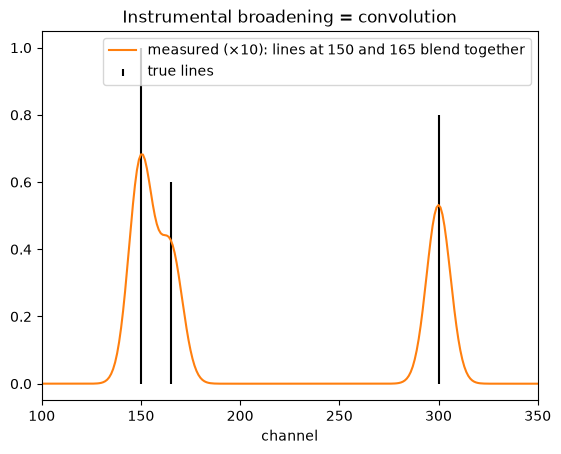

In [9]:
# BLOCK 8.7.1
N = 511                                # odd, so the PSF has a well-defined centre pixel
x = np.arange(N)
spectrum = np.zeros(N)
spectrum[[150, 165, 300]] = [1.0, 0.6, 0.8]                   # three sharp spectral lines
psf = np.exp(-0.5*((x - N//2)/6.0)**2); psf /= psf.sum()     # Gaussian instrument response

direct = np.convolve(spectrum, psf, mode='same')
via_fft = np.real(np.fft.ifft(np.fft.fft(spectrum) * np.fft.fft(np.fft.ifftshift(psf))))
print('direct and FFT convolution agree?', np.allclose(direct, via_fft))

plt.stem(x, spectrum, linefmt='k-', markerfmt=' ', basefmt=' ', label='true lines')
plt.plot(x, via_fft*10, label='measured (×10): lines at 150 and 165 blend together')
plt.xlim(100, 350); plt.xlabel('channel'); plt.legend(); plt.title('Instrumental broadening = convolution')
plt.show()

# 8.8 Spectral differentiation <a class="anchor" id="spectral-diff"></a>
Since $\frac{d}{dx}e^{ikx} = ik\,e^{ikx}$, differentiation in real space is multiplication by $ik$ in Fourier space. For smooth **periodic** functions this gives derivatives accurate to machine precision with very few points - so-called *spectral accuracy* - vastly better than finite differences. This is the basis of *spectral methods* for PDEs (and of the split-step method for the Schrödinger equation).

In [10]:
# BLOCK 8.8.1
for N in [8, 16, 32, 64]:
    x = np.linspace(0, 2*np.pi, N, endpoint=False)
    f = np.exp(np.sin(x))
    exact = np.cos(x)*f
    k = 2*np.pi*np.fft.fftfreq(N, d=x[1] - x[0])       # angular wavenumbers
    spectral = np.real(np.fft.ifft(1j*k*np.fft.fft(f)))
    fd = (np.roll(f, -1) - np.roll(f, 1))/(2*(x[1] - x[0]))
    print(f'N = {N:>2}: finite-difference error = {np.max(np.abs(fd - exact)):.1e},  '
          f'spectral error = {np.max(np.abs(spectral - exact)):.1e}')

N =  8: finite-difference error = 3.4e-01,  spectral error = 4.3e-03
N = 16: finite-difference error = 9.4e-02,  spectral error = 1.8e-07
N = 32: finite-difference error = 2.6e-02,  spectral error = 3.1e-15
N = 64: finite-difference error = 6.5e-03,  spectral error = 1.2e-14


# Problems <a class="anchor" id="problems"></a>

### Exercise 1 - Sunspots
Generate (or download from SILSO, the Royal Observatory of Belgium) the monthly sunspot number since 1749. Compute its power spectrum and find the period of the solar cycle in years.

### Exercise 2 - A musical note
Construct a 1-second "note" with a fundamental of 220 Hz and harmonics at 440, 660 and 880 Hz with amplitudes 1, 0.5, 0.3, 0.2, sampled at 8 kHz. Find the peaks of the spectrum. What do you see if you sample at only 1 kHz?

### Exercise 3 - Parseval's theorem
Verify numerically that $\sum_n |f_n|^2 = \frac{1}{N}\sum_k |F_k|^2$ for a random signal. What is the physical meaning of this result?

### Exercise 4 - Deconvolution
Add a small amount of noise to the blurred spectrum in BLOCK 8.7.1 and try to recover the true lines by dividing by the transform of the PSF. Then use a *Wiener filter*, $\tilde f_{\text{est}} = \tilde h\,\tilde g^*/(|\tilde g|^2 + \epsilon)$, and experiment with $\epsilon$. Can you separate the lines at 150 and 165?

In [11]:
# Start working here